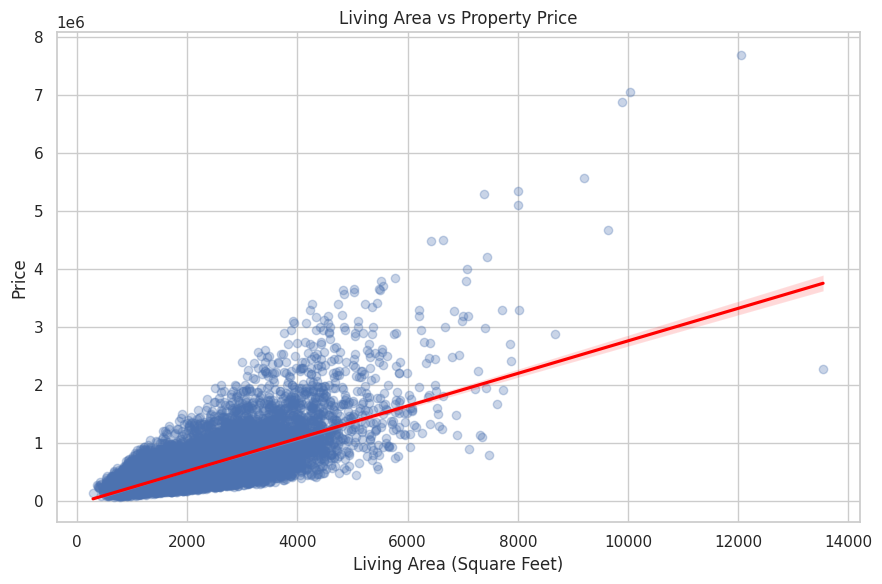

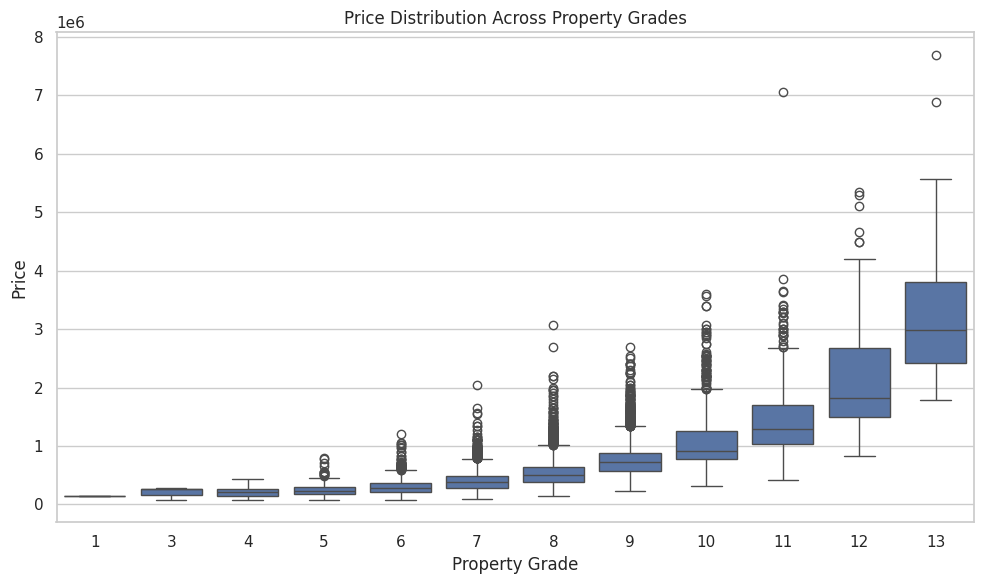

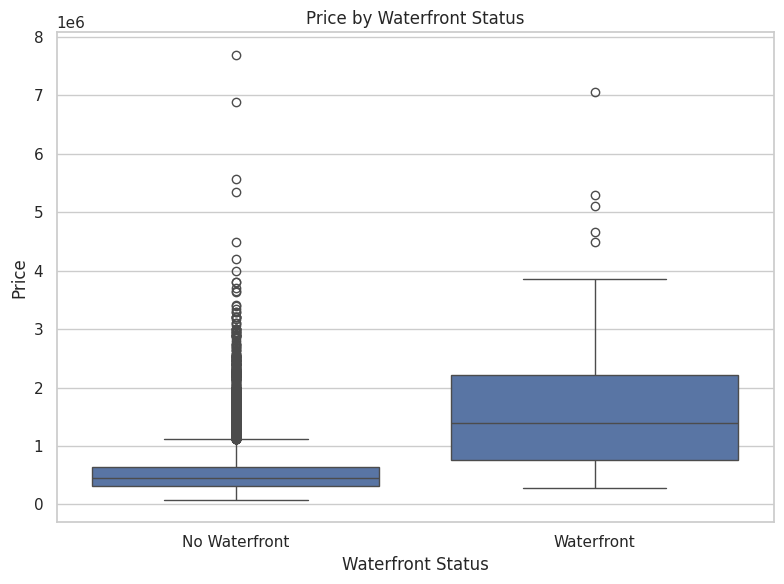

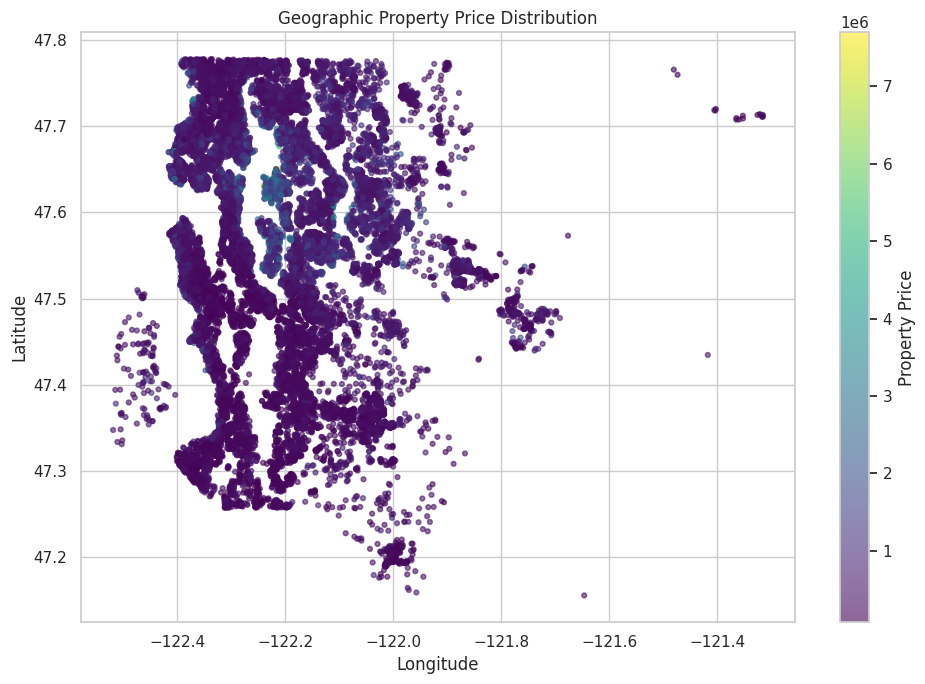

Top 10 High-Value Location Clusters
 lat_cluster  long_cluster  property_count  average_price  median_price  average_living_area
       47.57       -122.19               7   2.819714e+06     2500000.0          4868.571429
       47.64       -122.29               6   2.514667e+06     2570000.0          4125.000000
       47.64       -122.24               6   2.387650e+06     2075000.0          3973.333333
       47.62       -122.24              13   2.229227e+06     2100000.0          3821.923077
       47.63       -122.24               8   2.226750e+06     1603000.0          3862.500000
       47.56       -122.23               6   2.136000e+06     2298000.0          4426.666667
       47.62       -122.22              26   2.124067e+06     1720375.0          3811.923077
       47.73       -122.37               7   2.112643e+06     1680000.0          5351.428571
       47.69       -122.22               5   2.067600e+06     2350000.0          3889.000000
       47.63       -122.23        

In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/kc_house_data.csv")

df.columns = df.columns.str.strip()

df["price"] = pd.to_numeric(df["price"], errors="coerce")
df["sqft_living"] = pd.to_numeric(df["sqft_living"], errors="coerce")
df["grade"] = pd.to_numeric(df["grade"], errors="coerce")
df["waterfront"] = pd.to_numeric(df["waterfront"], errors="coerce")
df["lat"] = pd.to_numeric(df["lat"], errors="coerce")
df["long"] = pd.to_numeric(df["long"], errors="coerce")

df = df.dropna(subset=[
    "price", "sqft_living", "grade",
    "waterfront", "lat", "long"
])

df = df[
    (df["price"] > 0) &
    (df["sqft_living"] > 0)
]

sns.set_theme(style="whitegrid")

# 1. Living Area vs Price with Regression Line
plt.figure(figsize=(9, 6))
sns.regplot(
    data=df,
    x="sqft_living",
    y="price",
    scatter_kws={"alpha": 0.3},
    line_kws={"color": "red"}
)
plt.title("Living Area vs Property Price")
plt.xlabel("Living Area (Square Feet)")
plt.ylabel("Price")
plt.tight_layout()
plt.savefig("living_area_vs_price.png")
plt.show()

# 2. Price Distribution by Property Grade
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="grade", y="price")
plt.title("Price Distribution Across Property Grades")
plt.xlabel("Property Grade")
plt.ylabel("Price")
plt.tight_layout()
plt.savefig("price_by_grade.png")
plt.show()

# 3. Price Distribution by Waterfront Status
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x="waterfront", y="price")
plt.xticks([0, 1], ["No Waterfront", "Waterfront"])
plt.title("Price by Waterfront Status")
plt.xlabel("Waterfront Status")
plt.ylabel("Price")
plt.tight_layout()
plt.savefig("price_by_waterfront.png")
plt.show()

# 4. Geographic Price Heatmap
plt.figure(figsize=(10, 7))
scatter = plt.scatter(
    df["long"],
    df["lat"],
    c=df["price"],
    cmap="viridis",
    alpha=0.6,
    s=12
)
plt.colorbar(scatter, label="Property Price")
plt.title("Geographic Property Price Distribution")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.savefig("geographic_price_heatmap.png")
plt.show()

# High-Value Geographic Clusters
df["lat_cluster"] = df["lat"].round(2)
df["long_cluster"] = df["long"].round(2)

clusters = (
    df.groupby(["lat_cluster", "long_cluster"])
    .agg(
        property_count=("price", "size"),
        average_price=("price", "mean"),
        median_price=("price", "median"),
        average_living_area=("sqft_living", "mean")
    )
    .reset_index()
)

clusters = clusters[clusters["property_count"] >= 5]

clusters = clusters.sort_values(
    "average_price", ascending=False
)

clusters.to_csv("high_value_location_clusters.csv", index=False)

print("Top 10 High-Value Location Clusters")
print(clusters.head(10).to_string(index=False))

# Investment Summary Statistics
model = LinearRegression()
model.fit(df[["sqft_living"]], df["price"])

print("\nREAL ESTATE INVESTMENT SUMMARY")
print("Properties analyzed:", len(df))
print("Average price:", round(df["price"].mean(), 2))
print("Median price:", round(df["price"].median(), 2))
print("Average living area:", round(df["sqft_living"].mean(), 2))
print("Price change per additional square foot:",
      round(model.coef_[0], 2))
print("Regression R-squared:", round(model.score(
    df[["sqft_living"]], df["price"]
), 3))

print("\nTop 10 high-value locations saved to CSV.")
